### importing Libiraries

In [86]:
#importnant libraries
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

### Loading dataset

In [87]:

df=pd.read_csv("D:\Car price prediction\data\car_data.csv")


In [88]:
df.head()

,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [89]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  str    
 2   brand              15411 non-null  str    
 3   model              15411 non-null  str    
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  str    
 7   fuel_type          15411 non-null  str    
 8   transmission_type  15411 non-null  str    
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), str(6)
memory usage: 1.6 MB


In [6]:
df.describe()

,Unnamed: 0,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.000000,15411.000000,1.541100e+04,15411.000000,15411.000000,15411.000000,15411.000000,1.541100e+04
mean,9811.857699,6.036338,5.561648e+04,19.701151,1486.057751,100.588254,5.325482,7.749711e+05
std,5643.418542,3.013291,5.161855e+04,4.171265,521.106696,42.972979,0.807628,8.941284e+05
min,0.000000,0.000000,1.000000e+02,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,4906.500000,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,9872.000000,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.560000e+05
75%,14668.500000,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05
max,19543.000000,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07


### Data Cleaning

In [90]:
#checking null values
df.isnull().sum()

Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

In [91]:
#checking for duplicated values
df.duplicated().sum()

np.int64(0)

### Droping Unnecessary columns

In [92]:
df.columns

Index(['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven',
       'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine',
       'max_power', 'seats', 'selling_price'],
      dtype='str')

In [93]:
df.drop(['Unnamed: 0','car_name', 'brand'],axis=1,inplace=True)

### Numerical And Categerical Features

In [94]:
numerical_features=[feature for feature in df.columns if df[feature].dtype !="str"]
print("Numerical Features : ", len(numerical_features) )
print(numerical_features)
print("\n")

categorical_features=[feature for feature in df.columns if feature not in numerical_features]
print("Cactegorical Features : ", len(categorical_features))
print(categorical_features)


Numerical Features :  7
['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']


Cactegorical Features :  4
['model', 'seller_type', 'fuel_type', 'transmission_type']


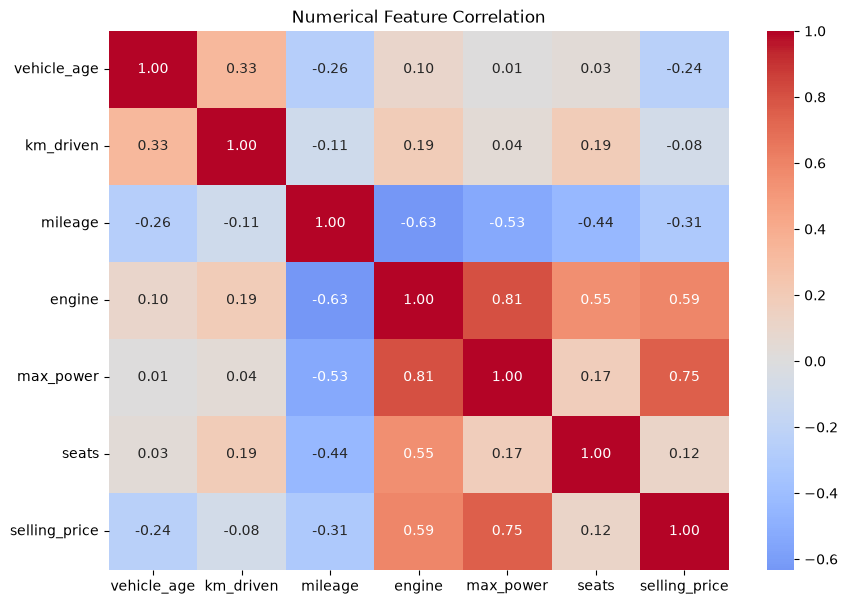

In [95]:
corr = df[numerical_features].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr, annot=True, fmt='.2f',
    cmap='coolwarm', center=0
)
plt.title('Numerical Feature Correlation')
plt.show()

### Independent and Dependent Features

In [97]:
X=df.drop("selling_price",axis=1)
y=df['selling_price']

In [98]:
X.shape,y.shape

((15411, 10), (15411,))

In [99]:
X.head()

,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats
0,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5
1,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5
2,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5
3,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5
4,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5


In [100]:
y.head()

0    120000
1    550000
2    215000
3    226000
4    570000
Name: selling_price, dtype: int64

### Feature Encoding and Scaling

In [101]:
print(categorical_features)

['model', 'seller_type', 'fuel_type', 'transmission_type']


In [102]:
df['model'].unique

<bound method Series.unique of 0            Alto
1           Grand
2             i20
3            Alto
4        Ecosport
           ...   
15406         i10
15407      Ertiga
15408       Rapid
15409      XUV500
15410        City
Name: model, Length: 15411, dtype: str>

In [103]:
df['model'].value_counts()

model
i20             906
Swift Dzire     890
Swift           781
Alto            778
City            757
               ... 
Altroz            1
C                 1
Ghost             1
Quattroporte      1
Gurkha            1
Name: count, Length: 120, dtype: int64

In [104]:
categorical_features

['model', 'seller_type', 'fuel_type', 'transmission_type']

In [105]:
print(df['seller_type'].unique())
print(df['fuel_type'].unique())
print(df['transmission_type'].unique())

<StringArray>
['Individual', 'Dealer', 'Trustmark Dealer']
Length: 3, dtype: str
<StringArray>
['Petrol', 'Diesel', 'CNG', 'LPG', 'Electric']
Length: 5, dtype: str
<StringArray>
['Manual', 'Automatic']
Length: 2, dtype: str


In [106]:
numerical_features

['vehicle_age',
 'km_driven',
 'mileage',
 'engine',
 'max_power',
 'seats',
 'selling_price']

In [107]:
df.columns

Index(['model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type',
       'transmission_type', 'mileage', 'engine', 'max_power', 'seats',
       'selling_price'],
      dtype='str')

In [108]:
#one hot encoding,Ordinal encoding  and Standard scaler using column Transformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler,OrdinalEncoder
from sklearn.compose import ColumnTransformer
OE=OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
OHE=OneHotEncoder(drop='first')
scaler=StandardScaler()

oe_features=['model']
ohe_features=['seller_type','transmission_type','fuel_type']
scaler_features=[feature for feature in X.columns if X[feature].dtype != "str"]

ct=ColumnTransformer(
    [
        
        ("Standardscaler",scaler,scaler_features),
        ("OrdinalEncoding",OE,oe_features),
        ("Onehotencoding",OHE,ohe_features)
    ],remainder="passthrough"
)

In [109]:
transformed_X=ct.fit_transform(X)

In [110]:
pd.DataFrame(transformed_X)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,0.983562,1.247335,-0.000276,-1.324259,-1.263352,-0.403022,7.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,-0.343933,-0.690016,-0.192071,-0.554718,-0.432571,-0.403022,54.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
2,1.647309,0.084924,-0.647583,-0.554718,-0.479113,-0.403022,118.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.983562,-0.360667,0.292211,-0.936610,-0.779312,-0.403022,7.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
4,-0.012060,-0.496281,0.735736,0.022918,-0.046502,-0.403022,38.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15406,0.983562,-0.869744,0.026096,-0.767733,-0.757204,-0.403022,117.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
15407,-1.339555,-0.728763,-0.527711,-0.216964,-0.220803,2.073444,42.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
15408,-0.012060,0.220539,0.344954,0.022918,0.068225,-0.403022,77.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
15409,-0.343933,72.541850,-0.887326,1.329794,0.917158,2.073444,114.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


### Separating data into training and testing

In [111]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(transformed_X,y)

In [115]:
pd.DataFrame(x_train),pd.DataFrame(y_train)

(             0         1         2         3         4         5      6    7   \
 0      2.311057  0.162844 -0.427019 -0.767733 -0.895668 -0.403022   84.0  0.0   
 1      0.651688  0.162418  0.718954  0.022918 -0.250125 -0.403022   38.0  0.0   
 2     -0.343933 -0.631896  0.407288 -0.554718 -0.406973 -0.403022   13.0  0.0   
 3     -1.007681 -0.786884 -0.383865 -0.550880 -0.276654 -0.403022   10.0  1.0   
 4     -0.012060 -0.108811  0.814851 -0.936610 -0.780708 -0.403022   23.0  1.0   
 ...         ...       ...       ...       ...       ...       ...    ...  ...   
 11553 -1.007681  0.278659  1.030620 -0.575827 -0.619438 -0.403022   54.0  1.0   
 11554 -0.675807 -0.504050  0.356941 -0.172826 -0.275956 -0.403022  118.0  0.0   
 11555 -1.339555 -0.283173 -0.801018  1.329794  0.451734  2.073444   85.0  0.0   
 11556 -0.012060  0.414274 -0.527711 -0.216964 -0.468408  2.073444   42.0  0.0   
 11557  2.642931 -0.399414 -0.000276 -1.324259 -1.263352 -0.403022    7.0  0.0   
 
         8    

### Creating function to evaluate model

In [116]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

def evaluate(true,predicted):
    mae=mean_absolute_error(true,predicted)
    mse=mean_squared_error(true,predicted)
    rmse=np.sqrt(mean_squared_error(true,predicted))
    R2_score=r2_score(true,predicted)
    return mae,mse,rmse,R2_score

### Training model with diffrent algorithms and model selction

In [117]:
#importing libraries
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor


In [118]:

models={
    "LinearRegression":LinearRegression(),
    "DecisionTree":DecisionTreeRegressor(),
    "svm":SVR(),
    "KNN":KNeighborsRegressor(),
    "RandomForest":RandomForestRegressor()
}


In [119]:
#trainig models
for i in range(len(list(models))):
    model=list(models.values())[i]
    model.fit(x_train,y_train)

    y_train_pred=model.predict(x_train)
    y_test_pred=model.predict(x_test)

    model_train_mae,model_train_mse,model_train_rmse,model_train_r2score=evaluate(y_train,y_train_pred)
    model_test_mae,model_test_mse,model_test_rmse,model_test_r2score=evaluate(y_test,y_test_pred)


    print(f"***{list(models.keys())[i]}***")
    
    print("Model Performance on Traning Dataset")

    print("Mean Absolute Error :",model_train_mae)
    print("Mean Squared Error :", model_train_mse)
    print("Root Mean Squared Error :", model_train_rmse)
    print("R2 score : ", model_train_r2score)


    print("Model Performance on Testing Dataset")

    print("Mean Absolute Error :",model_test_mae)
    print("Mean Squared Error :", model_test_mse)
    print("Root Mean Squared Error :", model_test_rmse)
    print("R2 score : ", model_test_r2score)


    print("=" * 45)






***LinearRegression***
Model Performance on Traning Dataset
Mean Absolute Error : 271937.1369236913
Mean Squared Error : 313819735027.095
Root Mean Squared Error : 560196.1576332839
R2 score :  0.6168387438342253
Model Performance on Testing Dataset
Mean Absolute Error : 266529.0217669506
Mean Squared Error : 240644443641.91132
Root Mean Squared Error : 490555.24015335046
R2 score :  0.6750576619411435
***DecisionTree***
Model Performance on Traning Dataset
Mean Absolute Error : 4812.58373915408
Mean Squared Error : 377973036.6103874
Root Mean Squared Error : 19441.528659300107
R2 score :  0.9995385101466231
Model Performance on Testing Dataset
Mean Absolute Error : 142780.95639761226
Mean Squared Error : 552701936889.4548
Root Mean Squared Error : 743439.2624078008
R2 score :  0.2536862397298292
***svm***
Model Performance on Traning Dataset
Mean Absolute Error : 400805.98266959237
Mean Squared Error : 867208755264.7866
Root Mean Squared Error : 931240.4390192614
R2 score :  -0.058826

### Hyperparameter tunning with Random Search CV

In [120]:
from sklearn.model_selection import RandomizedSearchCV


rf = RandomForestRegressor(random_state=42, n_jobs=-1)

param_grid = {
    'n_estimators': [100, 150, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [0.7, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=15,
    scoring='r2',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(x_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV R2 Score:", random_search.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.7, 'max_depth': 20}
Best CV R2 Score: 0.8393161668612751


In [124]:
hyperparameter_model = random_search.best_estimator_

hyperparameter_model.fit(x_train,y_train)

best_y_train_pred=hyperparameter_model.predict(x_train)

best_y_test_pred=hyperparameter_model.predict(x_test)

In [125]:
print("Traning Data performace")
hyperparameter_train_mae,hyperparameter_train_mse,hyperparameter_train_rmse,hyperparameter_train_r2score=evaluate(y_train,best_y_train_pred)
print("mean_absolute_error :",hyperparameter_train_mae)
print("mean_squared_error :",hyperparameter_train_mse)
print("Root mean swuared error :",hyperparameter_train_rmse)
print("r2_score :",hyperparameter_train_r2score)
print()
print("Testing Data Performnce")
hyperparameter_test_mae,hyperparameter_test_mse,hyperparameter_test_rmse,hyperparameter_test_r2score=evaluate(y_test,best_y_test_pred)
print("mean_absolute_error :",hyperparameter_test_mae)
print("mean_squared_error :",hyperparameter_test_mse)
print("Root mean swuared error :",hyperparameter_test_rmse)
print("r2_score :",hyperparameter_test_r2score)
print()

Traning Data performace
mean_absolute_error : 56179.19976628923
mean_squared_error : 26263534793.836926
Root mean swuared error : 162060.28135800865
r2_score : 0.9679332818820613

Testing Data Performnce
mean_absolute_error : 98971.33921661574
mean_squared_error : 68910190423.2582
Root mean swuared error : 262507.5054608119
r2_score : 0.9069505281180126



### Final model: Random Forest with default hyperparameters

### Tried RandomizedSearchCV and it did not improve test performance, so  kept the default model

In [126]:
best_model=RandomForestRegressor()

### Retraning model with the pipeline

In [127]:
from sklearn.pipeline import Pipeline
car_pipeline=Pipeline(
    [
        
        ("Preprocessor",ct),
        ("model",best_model)
    ]
)

In [129]:
#spliiting data again for pipeline
n_x_train,n_x_test,n_y_train,n_y_test=train_test_split(X,y,test_size=30,random_state=42)

In [130]:
car_pipeline.fit(n_x_train,n_y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['model','vehicle_age','km_driven',...,'engine','max_power','seats']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Standardscaler', ...), ('OrdinalEncoding', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed throug

In [131]:
new_y_train_pred=car_pipeline.predict(n_x_train)
new_y_test_pred=car_pipeline.predict(n_x_test)

### Performance of pipeline 

In [135]:
PL_model_test_mae,PL_model_test_mse,PL_model_test_rmse,PL_model_test_r2score=evaluate(new_y_test_pred,n_y_test)
PL_model_train_mae,PL_model_train_mse,PL_model_train_rmse,PL_model_train_r2score=evaluate(new_y_train_pred,n_y_train)



    
print(" Pipeline Model Performance on Traning Dataset")

print("Mean Absolute Error :",PL_model_train_mae)
print("Mean Squared Error :", PL_model_train_mse)
print("Root Mean Squared Error :", PL_model_train_rmse)
print("R2 score : ", PL_model_train_r2score)


print()

print("Pipeline Model Performance on Testing Dataset")

print("Mean Absolute Error :",PL_model_test_mae)
print("Mean Squared Error :", PL_model_test_mse)
print("Root Mean Squared Error :", PL_model_test_rmse)
print("R2 score : ", PL_model_test_r2score)

 Pipeline Model Performance on Traning Dataset
Mean Absolute Error : 38971.25064345749
Mean Squared Error : 14706455258.169199
Root Mean Squared Error : 121270.17464392965
R2 score :  0.9797571504860417

Pipeline Model Performance on Testing Dataset
Mean Absolute Error : 79199.04166666667
Mean Squared Error : 15089865824.070414
Root Mean Squared Error : 122840.8149764174
R2 score :  0.9576364314281873


### picking the model

In [136]:
import pickle
pickle.dump(car_pipeline,open("D:\Car price prediction\models\car_model.pkl","wb"))